# lintex: reviewing code a coding agent wrote

lintex is a single-pass AST linter for the mistakes LLM coding agents actually make, and it hands each finding back to the agent with a `why` and a `fix` it can act on.

| At a glance | |
|---|---|
| Package | `lintex` 0.1.0 (PyPI, MIT, by the owner of this repo). Pure Python, no dependencies on 3.11+. |
| Catches | Hallucinated or removed APIs, SQL built with f-strings, `eval`/`pickle`/`shell=True`/`verify=False`, insecure temp files, `except Exception: pass`, `# ... rest unchanged` placeholders, oversized functions |
| Runs as | `lintex check` on the CLI, a Claude Code `PostToolUse` hook, a git pre-commit hook, GitHub Actions annotations, or the `lintex.Linter` library API |

## What you will build

An AppSec review of a payments service that a Claude Code session just wrote for a fictional company. The code has fifteen-odd planted agent mistakes; you find them with lintex, tune the rules to the project, gate them at commit time, and then wire lintex into the agent loop so the next session fixes its own mistakes before a human ever sees them.

| Section | What you do | Time |
|---|---|---|
| Setup | Install, generate the agent-written service with faker | 2 min |
| Part 1: Quick start | Lint one file, read the pretty output, check the exit code | 5 min |
| Part 2: Working session | Lint the whole service, five output formats, `rules`/`explain`, `.lintex.toml`, inline ignores, `--changed`/`--staged` on a git repo, the Claude Code hook and its session ledger | 20 min |
| Part 3: Solving a critical problem | The 2 a.m. refund edit: an injection plus silently deleted fraud checks, caught by the hook in the same step, fixed, and proven at the commit and CI gates | 10 min |
| Part 4: Deep dive | The one-parse one-walk engine, name resolution and compat guards, writing a rule, exit codes, performance, limitations | 15 min |
| Benchmark | Recall, precision, latency and rule coverage against the planted ground truth, with ruff and bandit on the same files | 5 min |

## Setup

Everything runs offline. The pip cell only installs what is missing, so it is a no-op on a prepared machine.

In [1]:
import importlib.util, subprocess, sys

missing = [p for p in ("lintex", "faker", "pandas", "matplotlib", "ruff", "bandit") if importlib.util.find_spec(p) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
print("ready:", "nothing to install" if not missing else ", ".join(missing))

ready: nothing to install


In [2]:
import ast
import json
import os
import random
import shutil
import subprocess
import sys
import tempfile
import textwrap
import time
from pathlib import Path

import re

import pandas as pd
from faker import Faker

import lintex

Faker.seed(7)
random.seed(7)
fake = Faker()

# Run lintex as a subprocess, the way a hook or CI job would. NO_COLOR keeps the
# output plain so it renders the same here and on GitHub.
ENV = {k: v for k, v in os.environ.items() if k != "FORCE_COLOR"}
ENV.update({"NO_COLOR": "1", "PYTHONIOENCODING": "utf-8", "COLUMNS": "100"})

def lx(*args, cwd=None, stdin=None, show=True, env=None):
    proc = subprocess.run([sys.executable, "-m", "lintex", *args], cwd=cwd, input=stdin,
                          capture_output=True, text=True, env=env or ENV)
    if show:
        out = (proc.stdout + proc.stderr).rstrip()
        print(out)
        print(f"[exit {proc.returncode}]")
    return proc

print("lintex", lintex.__version__, "on Python", sys.version.split()[0])

lintex 0.1.0 on Python 3.13.18


In [3]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Circle, FancyArrowPatch

INK, PAPER, LINE = "#1f2328", "#ffffff", "#d0d7de"
FILL = {"step": "#eaeef2", "accent": "#ddf4ff", "warn": "#fff1e5", "good": "#dafbe1"}

def canvas(w=11, h=3.2):
    fig, ax = plt.subplots(figsize=(w, h), dpi=120)
    ax.set_xlim(0, w); ax.set_ylim(0, h); ax.axis("off")
    fig.patch.set_facecolor(PAPER)
    return fig, ax

def box(ax, x, y, w, h, text, kind="step", fs=9.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.12",
                                fc=FILL[kind], ec=LINE, lw=1.2))
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=fs, color=INK,
            family="DejaVu Sans", linespacing=1.4)

def dot(ax, x, y, r, text, kind="accent", fs=9.5):
    ax.add_patch(Circle((x, y), r, fc=FILL[kind], ec=LINE, lw=1.2))
    ax.text(x, y, text, ha="center", va="center", fontsize=fs, color=INK, family="DejaVu Sans")

def arrow(ax, x1, y1, x2, y2, label=None, fs=8.5):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=12,
                                 color=INK, lw=1.1, shrinkA=2, shrinkB=2))
    if label:
        ax.text((x1+x2)/2, (y1+y2)/2 + 0.16, label, ha="center", va="bottom", fontsize=fs,
                color="#57606a", family="DejaVu Sans", zorder=5,
                bbox=dict(fc=PAPER, ec="none", pad=1.5))

def note(ax, x, y, text, fs=9, ha="left"):
    ax.text(x, y, text, ha=ha, va="center", fontsize=fs, color="#57606a", family="DejaVu Sans",
            zorder=5, bbox=dict(fc=PAPER, ec="none", pad=1.5))

### The scenario

A Claude Code session was asked to add invoice lookup, log rotation and a profile sync to a small payments service. It touched four modules and wrote a fifth. The reviewer has the diff and thirty minutes. The code below is generated with faker so the names, tables and hostnames look like a real service, and the mistakes are the ones in lintex's rule table: each file carries a different family of them.

In [4]:
company = fake.company()
project = company.split()[0].lower().replace(",", "").replace("-", "")
reviewer = fake.name()
agent_session = fake.uuid4()
api_host = f"api.{fake.domain_name()}"
customers = [fake.email() for _ in range(3)]

WORK = Path(tempfile.mkdtemp(prefix=f"{project}-"))
SRC = WORK / "billing"
SRC.mkdir()

# The pre-agent version of db.py: short, parameterised, one piece of old debt
# (the swallowed exception) that was already there before the session started.
BEFORE_DB = textwrap.dedent(f"""
    # billing/db.py - invoice persistence for {company}
    import sqlite3

    DB_PATH = "billing.sqlite3"


    def connect():
        try:
            return sqlite3.connect(DB_PATH)
        except Exception:
            pass


    def invoice_by_id(cur, invoice_id):
        cur.execute("SELECT id, customer_email, amount_cents FROM invoices WHERE id = ?", (invoice_id,))
        return cur.fetchone()
""").lstrip()

AGENT_FILES = {}

AGENT_FILES["billing/db.py"] = textwrap.dedent(f"""
    # billing/db.py - invoice persistence for {company}
    import sqlite3

    DB_PATH = "billing.sqlite3"


    def connect():
        try:
            return sqlite3.connect(DB_PATH)
        except Exception:
            pass


    def invoice_by_id(cur, invoice_id):
        cur.execute("SELECT id, customer_email, amount_cents FROM invoices WHERE id = ?", (invoice_id,))
        return cur.fetchone()


    def invoices_for_customer(cur, email):
        # e.g. email = "{customers[0]}"
        cur.execute(f"SELECT id, amount_cents FROM invoices WHERE customer_email = '{{email}}'")
        return cur.fetchall()


    def void_invoice(cur, invoice_id):
        cur.execute("UPDATE invoices SET status = 'void' WHERE id = " + str(invoice_id))
        # ... rest of the implementation unchanged
""").lstrip()

AGENT_FILES["billing/ops.py"] = textwrap.dedent(f"""
    # billing/ops.py - operational helpers added by the agent
    import os
    import pickle
    import subprocess
    import tempfile

    import requests
    import yaml

    PROFILE_URL = "https://{api_host}/v2/profiles"


    def load_settings(path):
        with open(path) as fh:
            return yaml.load(fh)


    def restore_session(blob):
        return pickle.loads(blob)


    def rotate_logs(service):
        os.system("gzip /var/log/{project}/%s.log" % service)
        subprocess.run("tar czf /var/backups/" + service + ".tgz /var/log/" + service, shell=True)


    def export_csv(rows):
        path = tempfile.mktemp(suffix=".csv")
        with open(path, "w") as fh:
            for row in rows:
                fh.write(",".join(map(str, row)) + "\\n")
        os.chmod(path, 0o777)
        return path


    def sync_profile(customer_id):
        return requests.get(f"{{PROFILE_URL}}/{{customer_id}}", verify=False).json()
""").lstrip()

AGENT_FILES["billing/compat.py"] = textwrap.dedent(f"""
    # billing/compat.py - "compatibility" helpers; most of these APIs no longer exist
    from collections import Mapping
    from datetime import datetime
    from os.path import joinpath

    import fastjsonschema_turbo


    def is_mapping(value):
        return isinstance(value, Mapping)


    def stamp():
        return datetime.utcnow().isoformat()


    def dump(meta):
        for key, value in meta.iteritems():
            print(key, value)


    def audit_path(root, name):
        return joinpath(root, "audit", name)


    def validate(payload, schema):
        try:
            return fastjsonschema_turbo.validate(schema, payload)
        except:
            return None
""").lstrip()

# A tax-rate lookup written as one elif per country: realistic agent bloat.
countries = sorted({fake.country_code() for _ in range(60)})[:28]
branches = "\n".join(
    f"    {'if' if i == 0 else 'elif'} country == {c!r}:\n        rate = {random.randint(5, 25)}"
    for i, c in enumerate(countries)
)
AGENT_FILES["billing/tax.py"] = f"# billing/tax.py - VAT lookup\n\n\ndef vat_rate(country):\n{branches}\n    else:\n        rate = 0\n    return rate\n"

AGENT_FILES["billing/models.py"] = textwrap.dedent("""
    # billing/models.py - untouched by the agent
    from dataclasses import dataclass


    @dataclass(frozen=True)
    class Invoice:
        id: int
        customer_email: str
        amount_cents: int
        status: str = "open"
""").lstrip()

AGENT_FILES["billing/__init__.py"] = ""

for rel, text in AGENT_FILES.items():
    (WORK / rel).write_text(text)

print(f"Company   {company}\nReviewer  {reviewer}\nSession   {agent_session}\nWorkdir   {WORK}")
print("Files    ", ", ".join(sorted(p.name for p in SRC.glob("*.py"))))

Company   Gould-Foster
Reviewer  Roberto Davis
Session   81e74ef5-e8e2-4d94-8ed9-04759531985d
Workdir   /tmp/gouldfoster-o3zfvupc
Files     __init__.py, compat.py, db.py, models.py, ops.py, tax.py


Each file carries one family of mistakes, so the output of each run below is easy to read against this table.

| File | What the agent did | Rule family it trips |
|---|---|---|
| `billing/db.py` | Built two SQL statements with an f-string and `+`, left a `# ... rest of the implementation unchanged` where code used to be | LX2xx banned patterns, LX4xx artifacts |
| `billing/ops.py` | `yaml.load`, `pickle.loads`, `os.system`, `shell=True`, `tempfile.mktemp`, `chmod 0o777`, `verify=False` | LX203, LX204 |
| `billing/compat.py` | `collections.Mapping`, `datetime.utcnow()`, `.iteritems()`, a made-up `os.path.joinpath`, an import of a package that does not exist, bare `except:` | LX1xx hallucinations, LX403 |
| `billing/tax.py` | A 28-branch `if/elif` chain | LX3xx bloat |
| `billing/models.py` | Nothing: this is the control file | none |

---

## Part 1: Quick start

`lintex check PATH` is the whole interface for a first look. The pretty format groups findings by file, underlines the exact span, and shows the rationale once per rule so a long report stays readable.

In [5]:
proc = lx("check", "billing/db.py", cwd=WORK)

billing/db.py  4 errors
  10:5    ✖ error   LX402  Exception handler catches Exception and silently discards it.
         10 │ except Exception:
            │ ^^^^^^^^^^^^^^^^^
         why Silencing broad exceptions hides bugs (typos, None errors, bad data) and makes failures
             impossible to diagnose. Agents add this to make a traceback go away rather than fixing
             its cause.
         fix Catch only the specific exception you expect (e.g. `except FileNotFoundError:`), and
             handle it: log with `logger.exception(...)`, return a fallback, or re-raise. For an
             intentional ignore use `contextlib.suppress(SpecificError)`.

  21:17   ✖ error   LX201  SQL statement built with an f-string; interpolated values are not
                           escaped.
         21 │ cur.execute(f"SELECT id, amount_cents FROM invoices WHERE customer_email = '{email}'")
            │             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

Four findings, and each one is a complete instruction. The f-string SQL at line 21 gets a `fix` that names the right placeholder style per driver (`?` for sqlite3, which this file uses). The `+` concatenation at line 26 is the same rule, so its `why` is not repeated; pass `-v` to see it every time. The placeholder comment at line 27 is the one most reviewers miss by eye: it means the agent deleted whatever `void_invoice` used to do after the `UPDATE`.

The first finding is not the agent's. The `except Exception: pass` in `connect()` at line 10 was in the file before the session started; `check` lints whole files, so old debt shows up next to new mistakes. Part 2 uses `--changed`, which reports only the lines the agent touched.

The footer says there is no config file. That is fine for a first look; Part 2 writes one.

**Exit code 1** means at least one finding at or above the fail level (errors, by default). That is the number a hook or CI step keys on.

In [6]:
print("exit status:", proc.returncode)
print("control file:")
proc = lx("check", "billing/models.py", cwd=WORK)

exit status: 1
control file:


✔ All checks passed  · checked 1 file in 2 ms
[exit 0]


---

## Part 2: Working session

The reviewer's job has four steps: see everything, decide what the project cares about, make the gate stick at commit time, and make the agent fix its own mistakes next time. lintex has a feature for each.

### Everything at once, as a table

`--json` returns the same findings as the pretty output in a shape a script can read. Loading it into a DataFrame gives the review a spreadsheet view: which rules fire, where, and how often.

In [7]:
proc = lx("check", "billing", "--json", cwd=WORK, show=False)
report = json.loads(proc.stdout)
findings = pd.DataFrame(report["violations"])

print(f"{report['summary']} in {report['files_checked']} files, {report['duration_ms']} ms")
findings[["path", "line", "col", "code", "rule", "severity", "message"]]

{'total': 18, 'errors': 13, 'warnings': 5} in 6 files, 58.25 ms


,path,line,col,code,rule,severity,message
0,billing/compat.py,2,1,LX101,hallucinated-api,error,`collections.Mapping` was removed in Python 3.10.
1,billing/compat.py,4,1,LX102,nonexistent-stdlib-name,warning,`os.path` has no attribute or submodule `joinp...
2,billing/compat.py,14,12,LX101,hallucinated-api,warning,`datetime.datetime.utcnow` is deprecated (Pyth...
3,billing/compat.py,18,23,LX101,hallucinated-api,error,`.iteritems()` does not exist on Python 3 dict...
4,billing/compat.py,29,5,LX403,bare-except,warning,"Bare `except:` catches every exception, includ..."
5,billing/db.py,10,5,LX402,swallowed-exception,error,Exception handler catches Exception and silent...
6,billing/db.py,21,17,LX201,sql-string-interpolation,error,SQL statement built with an f-string; interpol...
7,billing/db.py,26,17,LX201,sql-string-interpolation,error,SQL statement built with string concatenation;...
8,billing/db.py,27,5,LX401,placeholder-code,error,Placeholder comment '... rest of the implement...
9,billing/ops.py,15,16,LX203,dangerous-call,error,`yaml.load()` without a safe Loader can constr...


In [8]:
by_rule = (findings.groupby(["code", "rule", "severity"]).size()
           .rename("count").reset_index().sort_values("count", ascending=False))
by_rule

,code,rule,severity,count
4,LX203,dangerous-call,error,5
3,LX201,sql-string-interpolation,error,2
0,LX101,hallucinated-api,error,2
5,LX204,insecure-file-operation,error,2
1,LX101,hallucinated-api,warning,1
2,LX102,nonexistent-stdlib-name,warning,1
6,LX301,function-too-long,warning,1
7,LX302,high-complexity,warning,1
8,LX401,placeholder-code,error,1
9,LX402,swallowed-exception,error,1


In [9]:
pd.crosstab(findings["path"], findings["code"].str[:3].map(
    {"LX1": "hallucination", "LX2": "banned pattern", "LX3": "bloat", "LX4": "artifact"}))

code,artifact,banned pattern,bloat,hallucination
path,,,,
billing/compat.py,1,0,0,4
billing/db.py,2,2,0,0
billing/ops.py,0,7,0,0
billing/tax.py,0,0,2,0


The crosstab is the review in one glance: `ops.py` is the security file, `compat.py` is the hallucination file, `tax.py` is bloat, `models.py` is clean. LX203 `dangerous-call` is the largest bucket because it covers seven different sinks (`eval`, `pickle`, `yaml.load`, `os.system`, `shell=True`, `verify=False`, and more); the agent hit five of them in one file.

Two things to check before trusting any of this. First, LX103 (`unresolvable-import`) did not fire on `fastjsonschema_turbo` because it is opt-in; the config section turns it on. Second, `tax.py` has two bloat warnings rather than errors, because length and complexity are judgement calls and the defaults treat them that way.

### The five output formats

Each format exists for a different consumer. The findings are identical; only the shape changes.

| Format | Consumer | Shape |
|---|---|---|
| `pretty` (default) | A person at a terminal | Grouped by file, underlined span, `why` once per rule |
| `full` | An agent reading hook output | Every finding with its own `why` and `fix`, no grouping |
| `concise` | Editors, `grep`, quick diffs | One `path:line:col: CODE message` per finding |
| `github` | GitHub Actions | `::error file=...,line=...::` workflow commands that annotate the PR diff |
| `json` | Harnesses, dashboards, this notebook | `{"summary": ..., "violations": [...]}` |

In [10]:
proc = lx("check", "billing/compat.py", "--format", "concise", cwd=WORK)

billing/compat.py:2:1: LX101 `collections.Mapping` was removed in Python 3.10.
billing/compat.py:4:1: LX102 `os.path` has no attribute or submodule `joinpath` (checked against Python 3.13).
billing/compat.py:14:12: LX101 `datetime.datetime.utcnow` is deprecated (Python 3.12) and returns a naive datetime.
billing/compat.py:18:23: LX101 `.iteritems()` does not exist on Python 3 dicts or pandas >= 2.0 objects.
billing/compat.py:29:5: LX403 Bare `except:` catches every exception, including KeyboardInterrupt and SystemExit.
✖ Found 2 errors and 3 warnings in 1 file  · checked 1 file in 21 ms
  LX101 hallucinated-api         ×3
  LX102 nonexistent-stdlib-name  ×1
  LX403 bare-except              ×1
  Each finding's `fix` line says what to write instead. `lintex explain CODE` has the full story;
  `# lintex: ignore[CODE]` silences a line on purpose.
[exit 1]


In [11]:
proc = lx("check", "billing/ops.py", "--format", "github", cwd=WORK, show=False)
annotations = [line for line in proc.stdout.splitlines() if line.startswith("::")]
print("\n".join(a[:140] + (" ..." if len(a) > 140 else "") for a in annotations[:4]))
print(f"... {len(annotations)} annotations total")

::error file=billing/ops.py,line=15,col=16,endLine=15,title=LX203 dangerous-call::`yaml.load()` without a safe Loader can construct arbitrar ...
::error file=billing/ops.py,line=19,col=12,endLine=19,title=LX203 dangerous-call::`pickle.loads()` can execute arbitrary code from its input ...
::error file=billing/ops.py,line=23,col=5,endLine=23,title=LX203 dangerous-call::`os.system()` runs its argument through the shell. Fix: Use ...
::error file=billing/ops.py,line=24,col=5,endLine=24,title=LX203 dangerous-call::`subprocess.run(..., shell=True)` passes the command throug ...
... 7 annotations total


The `github` lines are what a CI job prints so that GitHub draws the finding on the PR diff at that exact line; the `Fix:` text travels with it, so the reviewer sees the remedy without opening the tool. `%` is percent-encoded (`%25s`) because the workflow-command syntax requires it.

`full` is the format the Claude Code hook uses. It is deliberately verbose: an agent reads each finding in isolation, so every one carries its own `why` and `fix`.

In [12]:
proc = lx("check", "billing/db.py", "--format", "full", cwd=WORK, show=False)
print(proc.stdout.split("\n\n")[0])

billing/db.py:10:5: LX402 [error] Exception handler catches Exception and silently discards it.
    | except Exception:
    why: Silencing broad exceptions hides bugs (typos, None errors, bad data) and makes failures impossible to diagnose. Agents add this to make a traceback go away rather than fixing its cause.
    fix: Catch only the specific exception you expect (e.g. `except FileNotFoundError:`), and handle it: log with `logger.exception(...)`, return a fallback, or re-raise. For an intentional ignore use `contextlib.suppress(SpecificError)`.


### What a rule means: `rules` and `explain`

`lintex rules` lists every rule with its default severity and whether it is on under the current configuration. `lintex explain CODE` prints the rationale and the rule's options, which is where to look before deciding to ignore one.

In [13]:
proc = lx("rules", cwd=WORK)

Parsing
  LX001  syntax-error               on  error   File does not parse as Python.
Hallucinated imports and APIs
  LX101  hallucinated-api           on  error   Import or use of an API that was removed, deprecated, or never existed in Python 3.
  LX102  nonexistent-stdlib-name    on  error   Import or attribute access of a name that does not exist in a stdlib module.
  LX103  unresolvable-import       off  error   Top-level import that is not installed, not stdlib and not a local module.  (opt-in: add to `enable`)
Banned and insecure patterns
  LX201  sql-string-interpolation   on  error   SQL statement assembled with an f-string, .format(), % or + concatenation.
  LX202  raw-sql                   off  error   Raw SQL passed to execute()/text() in a project that forbids it.  (opt-in: add to `enable`)
  LX203  dangerous-call             on  error   eval/exec, unsafe deserialization, shell=True, or disabled TLS verification.
  LX204  insecure-file-operation    on  error   Race-prone 

In [14]:
proc = lx("explain", "LX204", cwd=WORK)

LX204 insecure-file-operation   error 

Race-prone temp files, world-writable permissions, unsafe archive extraction.

Flags `tempfile.mktemp`, hard-coded `/tmp/...` paths, permission modes that make files world-
writable, `os.umask(0)`, and `tarfile` `extractall()` without a `filter=`.

Silence one line with  # lintex: ignore[LX204]
[exit 0]


Every rule, with the specific sinks it knows about, so you can decide which ones match the threat model of your project:

| Code | Name | Default | Catches |
|---|---|---|---|
| LX001 | syntax-error | error | File does not parse, usually a truncated edit; no other rule runs on it |
| LX101 | hallucinated-api | error / warning | Removed, renamed or deprecated APIs from a curated pack plus typeshed: `collections.Mapping`, `distutils`, `numpy.float`, `openai.ChatCompletion`, `pydantic.BaseSettings`, `.iteritems()`, `datetime.utcnow()` |
| LX102 | nonexistent-stdlib-name | error | Names that do not exist in a stdlib module, checked against the running interpreter, with "did you mean" |
| LX103 | unresolvable-import | opt-in | Imports that are not installed, not stdlib and not local |
| LX201 | sql-string-interpolation | error | SQL text built with f-strings, `.format()`, `%` or `+` |
| LX202 | raw-sql | opt-in | Any raw SQL in `.execute()` / `text()`, for ORM-only projects |
| LX203 | dangerous-call | error | `eval`/`exec`, `pickle`/`marshal`/`dill` loads, `yaml.load` without a safe loader, `os.system`, `subprocess(shell=True)`, `verify=False` |
| LX204 | insecure-file-operation | error | `tempfile.mktemp`, world-writable modes, `os.umask(0)`, `extractall()` without `filter=`, hard-coded `/tmp` paths |
| LX205 | banned-api | error | Your own list of banned modules and functions with your own message |
| LX301 | function-too-long | warning | More than 50 code lines (configurable); names the blocks to extract |
| LX302 | high-complexity | warning | Cyclomatic complexity above 10 |
| LX303 | too-many-parameters | warning | More than 7 parameters |
| LX304 | deep-nesting | warning | Blocks nested more than 4 deep |
| LX305 | file-too-long | warning | More than 600 code lines in a module |
| LX401 | placeholder-code | error | `# ... existing code ...`, `# rest unchanged`, `your code here`; `# TODO: implement` is a warning |
| LX402 | swallowed-exception | error | Broad `except` whose body is `pass`, `continue` or `...` |
| LX403 | bare-except | warning | `except:` with no type |

### Configuration: `.lintex.toml`

A linter nobody tuned gets ignored. lintex reads the first of `.lintex.yaml`, `.lintex.toml` or `pyproject.toml` `[tool.lintex]` it finds walking up from the linted path. The config below is what an AppSec team would write for this service: turn on the opt-in import check, forbid raw SQL outside the repository layer with a message that points at the right module, ban `requests` in favour of an internal client, demote the one rule that is noise here, and exempt a legacy directory from the shell-call rule.

In [15]:
CONFIG = textwrap.dedent(f"""
    enable = ["LX103", "raw-sql"]
    ignore = ["LX403"]
    severity = {{ LX301 = "error" }}
    per-file-ignores = {{ "billing/legacy_*.py" = ["LX203"] }}

    [rules.raw-sql]
    hint = "Use the repository classes in billing/repos.py instead of hand-written SQL."

    [rules.banned-api]
    apis = {{ "requests" = "Use billing.http.client: it sets timeouts, retries and a CA bundle.", "print" = "Use structlog; print() bypasses the audit log." }}

    [rules.function-too-long]
    max-lines = 40
""").lstrip()
(WORK / ".lintex.toml").write_text(CONFIG)
print(CONFIG)

enable = ["LX103", "raw-sql"]
ignore = ["LX403"]
severity = { LX301 = "error" }
per-file-ignores = { "billing/legacy_*.py" = ["LX203"] }

[rules.raw-sql]
hint = "Use the repository classes in billing/repos.py instead of hand-written SQL."

[rules.banned-api]
apis = { "requests" = "Use billing.http.client: it sets timeouts, retries and a CA bundle.", "print" = "Use structlog; print() bypasses the audit log." }

[rules.function-too-long]
max-lines = 40



In [16]:
proc = lx("check", "billing", "--json", cwd=WORK, show=False)
after = pd.DataFrame(json.loads(proc.stdout)["violations"])

diff = pd.concat([findings.groupby("code").size().rename("before"),
                  after.groupby("code").size().rename("after")], axis=1).fillna(0).astype(int)
diff["change"] = diff["after"] - diff["before"]
diff[diff["change"] != 0]

,before,after,change
code,,,
LX403,1,0,-1
LX103,0,1,1
LX202,0,3,3
LX205,0,2,2


In [17]:
after.loc[after["code"].isin(["LX103", "LX202", "LX205"]), ["path", "line", "code", "message", "fix"]]

,path,line,code,message,fix
2,billing/compat.py,6,LX103,Cannot resolve import `fastjsonschema_turbo`: ...,"Use a module that exists, or add the real dist..."
5,billing/compat.py,19,LX205,`print` is banned in this project.,Use structlog; print() bypasses the audit log.
7,billing/db.py,15,LX202,Raw SQL is forbidden in this project.,Use the repository classes in billing/repos.py...
8,billing/db.py,21,LX202,Raw SQL is forbidden in this project.,Use the repository classes in billing/repos.py...
10,billing/db.py,26,LX202,Raw SQL is forbidden in this project.,Use the repository classes in billing/repos.py...
13,billing/ops.py,7,LX205,`requests` is banned in this project.,"Use billing.http.client: it sets timeouts, ret..."


Reading the delta: LX103 now catches the package that does not exist (`fastjsonschema_turbo`), LX202 flags the raw SQL with the team's own hint, LX205 flags `requests` and the `print()` in `compat.py` with the project's message, and LX403 is gone. The `severity` override moved `tax.py`'s long function from warning to error, so it now fails the build; that is a deliberate choice for a service that should never grow 28-branch functions.

`per-file-ignores` and `exclude` take glob patterns; keys can be written as `kebab-case` or `snake_case`. The same config as YAML needs `pip install "lintex[yaml]"`.

### Suppressing one line on purpose

Suppression is a reviewer's tool, not an agent's. The agent instructions in the README tell the model never to add `# lintex: ignore`; the human adds it, with a reason, where the code is a deliberate exception. Three forms:

| Comment | Effect |
|---|---|
| `# lintex: ignore[LX203]` | Silence one rule on this line (several: `ignore[LX203,LX204]`) |
| `# lintex: ignore` | Silence every rule on this line |
| `# lintex: skip-file` on its own line | Skip the whole file |

The `rotate_logs` shell call stays for now because it is on an internal box with no user input; the reviewer marks it and says why.

In [18]:
ops = WORK / "billing/ops.py"
flagged = 'os.system("gzip /var/log/' + project + '/%s.log" % service)'
assert flagged in ops.read_text()
ops.write_text(ops.read_text().replace(
    flagged, flagged + "  # lintex: ignore[LX203] fixed string, internal host, tracked in TICKET-4821"))

proc = lx("check", "billing/ops.py", "--format", "concise", "--select", "LX203", cwd=WORK)

billing/ops.py:15:16: LX203 `yaml.load()` without a safe Loader can construct arbitrary Python objects.
billing/ops.py:19:12: LX203 `pickle.loads()` can execute arbitrary code from its input.
billing/ops.py:24:5: LX203 `subprocess.run(..., shell=True)` passes the command through the shell.
billing/ops.py:37:12: LX203 `requests.get(..., verify=False)` disables TLS certificate verification.
✖ Found 4 errors in 1 file  · checked 1 file in 23 ms
  LX203 dangerous-call  ×4
  Each finding's `fix` line says what to write instead. `lintex explain CODE` has the full story;
  `# lintex: ignore[CODE]` silences a line on purpose.
[exit 1]


`os.system` is gone from the list; `subprocess.run(..., shell=True)` on the next line is still reported because the marker only covers its own line. `--select LX203` on the command line narrows the run to one rule (prefixes work too: `--select LX2` is every banned-pattern rule), and `--ignore` / `--enable` / `--fail-on` override the config file the same way.

### Gating at commit time: `--changed`, `--staged` and the pre-commit hook

Adopting a linter on a codebase that already has findings is the usual blocker. `--changed` compares the working tree with the merge base of the default branch and reports only findings that touch a changed line; new files are checked in full. `--staged` lints the index, which is what will actually be committed, so an unstaged fix cannot fool it.

The repo below has the pre-agent `db.py` on `main`. The agent's version then lands in the working tree.

In [19]:
REPO = Path(tempfile.mkdtemp(prefix="repo-"))
(REPO / "billing").mkdir()
GIT = ["git", "-c", "user.name=" + reviewer, "-c", "user.email=appsec@" + api_host.split(".", 1)[1],
       "-c", "commit.gpgsign=false"]

def git(*args, check=True):
    return subprocess.run([*GIT, *args], cwd=REPO, capture_output=True, text=True, check=check, env=ENV)

git("init", "-q", "-b", "main")
(REPO / "billing/models.py").write_text(AGENT_FILES["billing/models.py"])
(REPO / "billing/db.py").write_text(BEFORE_DB)
git("add", "."); git("commit", "-q", "-m", "billing: initial invoice lookup")

# The agent's edit arrives in the working tree.
(REPO / "billing/db.py").write_text(AGENT_FILES["billing/db.py"])
print(git("status", "--short").stdout)
proc = lx("check", "--changed=main", cwd=REPO)

 M billing/db.py



billing/db.py  3 errors
  21:17   ✖ error   LX201  SQL statement built with an f-string; interpolated values are not
                           escaped.
         21 │ cur.execute(f"SELECT id, amount_cents FROM invoices WHERE customer_email = '{email}'")
            │             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
         why Interpolating values into SQL text allows SQL injection whenever any value is
             influenced by user input, and breaks on quotes in ordinary data.
         fix Use bound parameters and pass values separately, e.g. `cur.execute("SELECT * FROM users
             WHERE id = %s", (user_id,))` (placeholder style depends on the driver: `?` for sqlite3,
             `%s` for psycopg/MySQLdb, `:name` with SQLAlchemy `text()`). Identifiers such as table
             or column names cannot be bound - check them against an explicit allow-list.

  26:17   ✖ error   LX201  SQL statement built with string concatenation; interpolat

The pre-existing `except Exception: pass` in `connect()` is not reported: it is on an unchanged line, so it is somebody else's debt and not this review's. The three new findings are. The note at the bottom says which base was used and that it resolved to a merge base, so a reviewer on a feature branch gets the same answer as CI.

Without `=main`, `--changed` looks for `origin/HEAD`, then `origin/main`, `origin/master`, `main`, `master`.

In [20]:
print("nothing staged yet:")
lx("check", "--staged", "--format", "concise", cwd=REPO)
git("add", "billing/db.py")
print("\nafter git add:")
proc = lx("check", "--staged", "--format", "concise", cwd=REPO)

nothing staged yet:


✔ All checks passed  · checked 0 files in 8 ms
[exit 0]

after git add:


billing/db.py:10:5: LX402 Exception handler catches Exception and silently discards it.
billing/db.py:21:17: LX201 SQL statement built with an f-string; interpolated values are not escaped.
billing/db.py:26:17: LX201 SQL statement built with string concatenation; interpolated values are not escaped.
billing/db.py:27:5: LX401 Placeholder comment '... rest of the implementation unchanged' stands in for code that is not there.
✖ Found 4 errors in 1 file  · checked 1 file in 38 ms
  LX201 sql-string-interpolation  ×2
  LX402 swallowed-exception       ×1
  LX401 placeholder-code          ×1
  Each finding's `fix` line says what to write instead. `lintex explain CODE` has the full story;
  `# lintex: ignore[CODE]` silences a line on purpose.
[exit 1]


In [21]:
lx("install-hook", "git", cwd=REPO)
hook = REPO / ".git/hooks/pre-commit"
print(hook.read_text())
commit = git("commit", "-q", "-m", "billing: customer invoice lookup", check=False)
# git relays hook output on its own stderr.
summary = next((l for l in commit.stderr.splitlines() if re.search(r"Found \d+ error", l)), "")
print(f"git commit exit {commit.returncode}; the hook printed: {summary.strip()!r}")
print("commits on main:", git("rev-list", "--count", "HEAD").stdout.strip())

Installed git pre-commit hook at /tmp/repo-uvnxfoqy/.git/hooks/pre-commit
[exit 0]
#!/bin/sh
# installed by lintex: lint staged Python files before committing.
# Re-install with `lintex install-hook git --force`; bypass once with `git commit --no-verify`.
if command -v lintex >/dev/null 2>&1; then
    exec lintex check --staged
fi
exec "/usr/local/bin/python3" -m lintex check --staged



git commit exit 1; the hook printed: '✖ Found 4 errors in 1 file  · checked 1 file in 19 ms'
commits on main: 1


The hook is eight lines of `sh`: it runs `lintex check --staged` and falls back to the interpreter that installed lintex if the console script is not on `PATH`. The commit fails with exit 1 and the findings on stdout. `git commit --no-verify` bypasses it once; `lintex install-hook git --force` replaces a hook that lintex did not write (by default it refuses to overwrite one).

### Closing the loop: the Claude Code hook

The commit gate is the last line. The first line is the agent loop itself: lintex registers as a Claude Code `PostToolUse` hook on `Edit|Write|MultiEdit`, lints the file the agent just wrote, and if it finds anything exits with status 2 and prints the findings to stderr. Claude Code passes that text back to the model as the tool result, so the fix happens in the next step, while the agent still has the context.

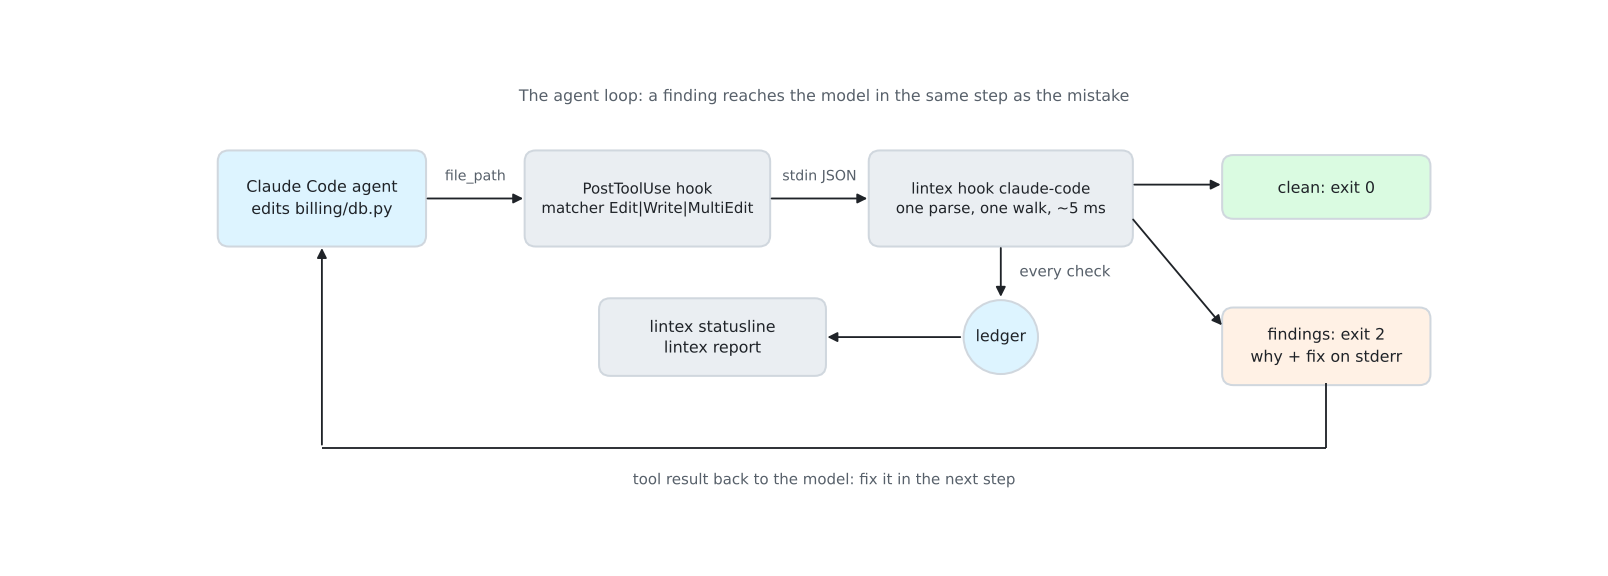

In [22]:
fig, ax = canvas(13.4, 4.8)
box(ax, 0.2, 2.9, 2.2, 1.0, "Claude Code agent\nedits billing/db.py", kind="accent")
box(ax, 3.5, 2.9, 2.6, 1.0, "PostToolUse hook\nmatcher Edit|Write|MultiEdit", fs=9)
box(ax, 7.2, 2.9, 2.8, 1.0, "lintex hook claude-code\none parse, one walk, ~5 ms", fs=9)
box(ax, 11.0, 3.2, 2.2, 0.65, "clean: exit 0", kind="good")
box(ax, 11.0, 1.4, 2.2, 0.8, "findings: exit 2\nwhy + fix on stderr", kind="warn")
dot(ax, 8.6, 1.9, 0.4, "ledger")
box(ax, 4.3, 1.5, 2.4, 0.8, "lintex statusline\nlintex report")

arrow(ax, 2.4, 3.4, 3.5, 3.4, "file_path")
arrow(ax, 6.1, 3.4, 7.2, 3.4, "stdin JSON")
arrow(ax, 10.0, 3.55, 11.0, 3.55)
arrow(ax, 10.0, 3.2, 11.0, 2.0)
arrow(ax, 8.6, 2.9, 8.6, 2.3)
note(ax, 8.8, 2.6, "every check")
arrow(ax, 8.2, 1.9, 6.7, 1.9)

# return path: findings -> down -> left -> up into the agent
ax.plot([12.1, 12.1], [1.4, 0.7], color=INK, lw=1.1, solid_capstyle="butt")
ax.plot([12.1, 1.3], [0.7, 0.7], color=INK, lw=1.1, solid_capstyle="butt")
arrow(ax, 1.3, 0.7, 1.3, 2.9)
note(ax, 6.7, 0.35, "tool result back to the model: fix it in the next step", ha="center")
note(ax, 6.7, 4.5, "The agent loop: a finding reaches the model in the same step as the mistake", fs=9.5, ha="center")
plt.show()

In [23]:
# A project that already has some Claude Code settings, to show the merge.
claude_dir = WORK / ".claude"
claude_dir.mkdir()
(claude_dir / "settings.json").write_text(json.dumps(
    {"permissions": {"allow": ["Bash(pytest:*)"]}}, indent=2))

lx("install-hook", "claude-code", cwd=WORK)
print((claude_dir / "settings.json").read_text())
proc = lx("install-hook", "claude-code", cwd=WORK)

Added lintex PostToolUse hook to /tmp/gouldfoster-o3zfvupc/.claude/settings.json
[exit 0]
{
  "permissions": {
    "allow": [
      "Bash(pytest:*)"
    ]
  },
  "hooks": {
    "PostToolUse": [
      {
        "matcher": "Edit|Write|MultiEdit",
        "hooks": [
          {
            "type": "command",
            "command": "lintex hook claude-code"
          }
        ]
      }
    ]
  }
}



lintex hook already present in /tmp/gouldfoster-o3zfvupc/.claude/settings.json
[exit 0]


`install-hook claude-code` merges one `PostToolUse` entry into `.claude/settings.json` and leaves everything else in the file alone; running it twice is a no-op. `--scope local` writes `settings.local.json` (not committed) and `--scope user` writes `~/.claude/settings.json`.

The hook reads the Claude Code payload on stdin. The cell below sends the same JSON Claude Code would send after the agent wrote `billing/db.py`, with the session ledger pointed at a temp directory so this notebook leaves nothing in your cache.

In [24]:
LEDGER = WORK / ".ledger"
HOOK_ENV = {**ENV, "LINTEX_LEDGER_DIR": str(LEDGER)}

def post_tool_use(rel_path, tool="Edit"):
    payload = {"session_id": agent_session, "tool_name": tool, "cwd": str(WORK),
               "tool_input": {"file_path": str(WORK / rel_path)}}
    return lx("hook", "claude-code", cwd=WORK, stdin=json.dumps(payload), env=HOOK_ENV)

proc = post_tool_use("billing/db.py")

lintex found 7 issue(s) in the file(s) you just edited. Fix them before continuing:

/tmp/gouldfoster-o3zfvupc/billing/db.py:10:5: LX402 [error] Exception handler catches Exception and silently discards it.
    | except Exception:
    why: Silencing broad exceptions hides bugs (typos, None errors, bad data) and makes failures impossible to diagnose. Agents add this to make a traceback go away rather than fixing its cause.
    fix: Catch only the specific exception you expect (e.g. `except FileNotFoundError:`), and handle it: log with `logger.exception(...)`, return a fallback, or re-raise. For an intentional ignore use `contextlib.suppress(SpecificError)`.

/tmp/gouldfoster-o3zfvupc/billing/db.py:15:5: LX202 [error] Raw SQL is forbidden in this project.
    | cur.execute("SELECT id, customer_email, amount_cents FROM invoices WHERE id = ?", (invoice_id,))
    why: The project configuration enables LX202: database access must go through the shared data-access layer so queries stay consis

Exit 2 is the Claude Code convention for "block and show the model this stderr". The text is the `full` format: each finding stands alone with the offending line, the `why` and the `fix`, because the model will read it without the rest of the file in front of it.

Seven issues rather than the four from Part 1, because the project config is now in force: LX202 `raw-sql` fires on every `execute()` with the team's hint, and the hook reports warnings as well as errors by default (`lintex hook claude-code --fail-on error` relaxes that).

Now the agent does what the `fix` lines say: bound parameters for both statements, a specific exception in `connect()`, and the elided code restored. The hook runs again on the new write.

In [25]:
FIXED_DB = AGENT_FILES["billing/db.py"].replace(
    "    except Exception:\n        pass",
    "    except sqlite3.OperationalError as exc:\n        raise RuntimeError(f\"cannot open {DB_PATH}\") from exc",
).replace(
    "cur.execute(f\"SELECT id, amount_cents FROM invoices WHERE customer_email = '{email}'\")",
    "cur.execute(\"SELECT id, amount_cents FROM invoices WHERE customer_email = ?\", (email,))",
).replace(
    "    cur.execute(\"UPDATE invoices SET status = 'void' WHERE id = \" + str(invoice_id))\n"
    "    # ... rest of the implementation unchanged\n",
    "    cur.execute(\"UPDATE invoices SET status = 'void' WHERE id = ?\", (invoice_id,))\n"
    "    cur.connection.commit()\n    return cur.rowcount == 1\n",
)
(WORK / "billing/db.py").write_text(FIXED_DB)
proc = post_tool_use("billing/db.py", tool="Write")

lintex found 3 issue(s) in the file(s) you just edited. Fix them before continuing:

/tmp/gouldfoster-o3zfvupc/billing/db.py:15:5: LX202 [error] Raw SQL is forbidden in this project.
    | cur.execute("SELECT id, customer_email, amount_cents FROM invoices WHERE id = ?", (invoice_id,))
    why: The project configuration enables LX202: database access must go through the shared data-access layer so queries stay consistent, typed and reviewable.
    fix: Use the repository classes in billing/repos.py instead of hand-written SQL.

/tmp/gouldfoster-o3zfvupc/billing/db.py:21:5: LX202 [error] Raw SQL is forbidden in this project.
    | cur.execute("SELECT id, amount_cents FROM invoices WHERE customer_email = ?", (email,))
    why: The project configuration enables LX202: database access must go through the shared data-access layer so queries stay consistent, typed and reviewable.
    fix: Use the repository classes in billing/repos.py instead of hand-written SQL.

/tmp/gouldfoster-o3zfvupc/bi

In [26]:
proc = lx("report", cwd=WORK, env=HOOK_ENV)

lintex ledger · gouldfoster-o3zfvupc · last 24h
lintex ▮▮ ✖ 3 · 4 fixed
7 caught across 2 edits of 1 file · 4 fixed by the agent · 3 still open

  LX202 raw-sql                   caught   3  fixed   0  3 open
  LX201 sql-string-interpolation  caught   2  fixed   2  all fixed
  LX402 swallowed-exception       caught   1  fixed   1  all fixed
  LX401 placeholder-code          caught   1  fixed   1  all fixed

Still open
  ✖ billing/db.py:15  LX202 Raw SQL is forbidden in this project.
  ✖ billing/db.py:21  LX202 Raw SQL is forbidden in this project.
  ✖ billing/db.py:26  LX202 Raw SQL is forbidden in this project.
[exit 0]


The injection, the swallowed exception and the placeholder are gone. What is still open is the raw-SQL policy on all three statements, and that is right: moving queries behind `billing/repos.py` is a refactor the reviewer should ask for explicitly, not something the agent should improvise in a hook loop.

The ledger is the audit trail of the session: what the hook caught, what the agent fixed on its next edit, and what is still open, per rule. For a reviewer this is the difference between "the agent ran a linter" and evidence. `--since 7d`, `--all`, `--session ID`, `--json` and `--clear` are the other switches; `ledger = false` in the config turns recording off.

`lintex statusline` renders the same ledger as a strip in Claude Code's status line while the agent works: one block per checked edit, then open counts and the fixed total. `install-hook statusline` sets it; `--segment` prints only the lintex part for embedding in an existing status script.

In [27]:
status_payload = json.dumps({"model": {"display_name": "Claude"}, "workspace": {"current_dir": str(WORK)},
                             "session_id": agent_session})
proc = lx("statusline", "--no-color", cwd=WORK, stdin=status_payload, env=HOOK_ENV)

Claude · gouldfoster-o3zfvupc · lintex ▮▮ ✖ 3 · 4 fixed
[exit 0]


### The library API

Everything above is available in-process. `lint_source` lints a string; `Linter(config)` is built once and reused across files, which is what the hook and the CLI do internally.

In [28]:
from lintex import Linter, lint_source, load_config

snippet = f'cur.execute("DELETE FROM invoices WHERE customer_email = \'%s\'" % "{customers[1]}")\n'
for v in lint_source(snippet, path="snippet.py"):
    print(v.code, v.line, v.col, v.severity.value, "-", v.message)
    print("  fix:", v.fix[:90], "...")

linter = Linter(load_config(WORK))          # picks up .lintex.toml
result = linter.lint_paths([WORK / "billing"])
print(f"\n{result.files_checked} files, {result.error_count} errors, "
      f"{result.warning_count} warnings, {result.duration_ms:.1f} ms, failed={result.failed(linter.config.fail_on)}")
pd.DataFrame(result.to_dict()["violations"])[["path", "line", "code", "severity"]].head(6)


6 files, 15 errors, 3 warnings, 27.9 ms, failed=True


,path,line,code,severity
0,/tmp/gouldfoster-o3zfvupc/billing/compat.py,2,LX101,error
1,/tmp/gouldfoster-o3zfvupc/billing/compat.py,4,LX102,warning
2,/tmp/gouldfoster-o3zfvupc/billing/compat.py,6,LX103,error
3,/tmp/gouldfoster-o3zfvupc/billing/compat.py,14,LX101,warning
4,/tmp/gouldfoster-o3zfvupc/billing/compat.py,18,LX101,error
5,/tmp/gouldfoster-o3zfvupc/billing/compat.py,19,LX205,error


---

## Part 3: Solving a critical problem

### The 2 a.m. refund edit

`billing/refunds.py` is the one module in this service a customer can reach directly: the support portal calls `issue_refund()` with the invoice id and a free-text reason the customer typed. The on-call engineer asked a Claude Code session, overnight, to "add the reason to the audit row and make refunds idempotent". The session made the change at 02:14, the tests still passed, and the pull request was waiting for the morning.

| | |
|---|---|
| What the agent did | Interpolated the customer-typed `reason` into an `UPDATE`, replaced the daily-cap check with `# ... existing logic unchanged (daily cap)`, and wrapped the audit write in `except Exception: pass` |
| What ships if nobody notices | A SQL injection on a customer-controlled field in the refund path, no daily refund cap, and audit rows that silently stop being written |
| How it is found without lintex | By the first attacker who types `'; UPDATE invoices SET status='refunded' --` into the reason box, or by finance three weeks later |
| Who gets paged | The on-call payments engineer, then the reviewer who approved the PR, then whoever owns the incident write-up |

Three gates stand between that edit and production, and lintex is wired into each. The rest of this part runs them in order on the real edit.

| Gate | What runs | What it must do |
|---|---|---|
| 1. The agent loop | `lintex hook claude-code` after the `Write` | Block the step and hand the model the fix |
| 2. The commit | `lintex check --staged` from the pre-commit hook | Refuse the commit if the agent ignored gate 1 |
| 3. CI on the PR | `lintex check --changed=main --format github` | Annotate the exact lines and fail the job |

In [29]:
REPO2 = Path(tempfile.mkdtemp(prefix="refunds-"))
(REPO2 / "billing").mkdir()
def git2(*args, check=True):
    return subprocess.run([*GIT, *args], cwd=REPO2, capture_output=True, text=True, check=check, env=ENV)

REFUNDS_BEFORE = textwrap.dedent(f"""
    # billing/refunds.py - customer-initiated refunds for {company}
    import sqlite3

    DAILY_REFUND_CAP_CENTS = 50_000


    def refunded_today_cents(cur, customer_email):
        cur.execute(
            "SELECT COALESCE(SUM(amount_cents), 0) FROM refunds "
            "WHERE customer_email = ? AND created_at >= date('now')",
            (customer_email,),
        )
        return cur.fetchone()[0]


    def issue_refund(cur, invoice_id, customer_email, amount_cents):
        if refunded_today_cents(cur, customer_email) + amount_cents > DAILY_REFUND_CAP_CENTS:
            raise ValueError("daily refund cap exceeded; route to a human")
        cur.execute("UPDATE invoices SET status = 'refunded' WHERE id = ? AND status = 'paid'", (invoice_id,))
        cur.execute(
            "INSERT INTO refunds (invoice_id, customer_email, amount_cents) VALUES (?, ?, ?)",
            (invoice_id, customer_email, amount_cents),
        )
        return cur.rowcount == 1
""").lstrip()

REFUNDS_0214 = textwrap.dedent(f"""
    # billing/refunds.py - customer-initiated refunds for {company}
    import sqlite3

    DAILY_REFUND_CAP_CENTS = 50_000


    def refunded_today_cents(cur, customer_email):
        cur.execute(
            "SELECT COALESCE(SUM(amount_cents), 0) FROM refunds "
            "WHERE customer_email = ? AND created_at >= date('now')",
            (customer_email,),
        )
        return cur.fetchone()[0]


    def issue_refund(cur, invoice_id, customer_email, amount_cents, reason=""):
        # ... existing logic unchanged (daily cap)
        cur.execute(
            f"UPDATE invoices SET status = 'refunded', refund_reason = '{{reason}}' "
            f"WHERE id = {{invoice_id}} AND status = 'paid'"
        )
        if cur.rowcount == 0:
            return False  # already refunded: idempotent
        try:
            cur.execute(
                "INSERT INTO refunds (invoice_id, customer_email, amount_cents, reason) VALUES (?, ?, ?, ?)",
                (invoice_id, customer_email, amount_cents, reason),
            )
        except Exception:
            pass
        return True
""").lstrip()

git2("init", "-q", "-b", "main")
(REPO2 / "pyproject.toml").write_text('[project]\nname = "billing"\nrequires-python = ">=3.11"\n\n[tool.lintex]\n')
(REPO2 / "billing/refunds.py").write_text(REFUNDS_BEFORE)
git2("add", "."); git2("commit", "-q", "-m", "billing: refunds with daily cap")
print("main is clean:")
proc = lx("check", "billing", "--format", "concise", cwd=REPO2)

# 02:14 - the agent writes its version.
(REPO2 / "billing/refunds.py").write_text(REFUNDS_0214)
print("\nthe diff the reviewer would see in the morning:")
print(git2("diff", "--stat").stdout)
print("\n".join(l for l in git2("diff", "-U0").stdout.splitlines()
                if l.startswith(("+", "-")) and not l.startswith(("+++", "---"))))

main is clean:


✔ All checks passed  · checked 1 file in 11 ms
[exit 0]

the diff the reviewer would see in the morning:
 billing/refunds.py | 21 ++++++++++++++-------
 1 file changed, 14 insertions(+), 7 deletions(-)

-def issue_refund(cur, invoice_id, customer_email, amount_cents):
-    if refunded_today_cents(cur, customer_email) + amount_cents > DAILY_REFUND_CAP_CENTS:
-        raise ValueError("daily refund cap exceeded; route to a human")
-    cur.execute("UPDATE invoices SET status = 'refunded' WHERE id = ? AND status = 'paid'", (invoice_id,))
+def issue_refund(cur, invoice_id, customer_email, amount_cents, reason=""):
+    # ... existing logic unchanged (daily cap)
-        "INSERT INTO refunds (invoice_id, customer_email, amount_cents) VALUES (?, ?, ?)",
-        (invoice_id, customer_email, amount_cents),
+        f"UPDATE invoices SET status = 'refunded', refund_reason = '{reason}' "
+        f"WHERE id = {invoice_id} AND status = 'paid'"
-    return cur.rowcount == 1
+    if cur.rowcount =

The diff reads as plausible at 2 a.m. and at 9 a.m.: a new parameter, an idempotency guard, a `try` around the insert. The two dangerous lines are the quietest ones. `- if refunded_today_cents(...)` is the daily cap leaving the file, and `+ # ... existing logic unchanged (daily cap)` is the agent's note that it meant to keep it.

### Gate 1: the hook, in the same step as the edit

In [30]:
LEDGER2 = REPO2 / ".ledger"
HOOK_ENV2 = {**ENV, "LINTEX_LEDGER_DIR": str(LEDGER2)}
night_session = fake.uuid4()

def refunds_hook(tool="Write"):
    payload = {"session_id": night_session, "tool_name": tool, "cwd": str(REPO2),
               "tool_input": {"file_path": str(REPO2 / "billing/refunds.py")}}
    return lx("hook", "claude-code", cwd=REPO2, stdin=json.dumps(payload), env=HOOK_ENV2)

proc = refunds_hook()

lintex found 3 issue(s) in the file(s) you just edited. Fix them before continuing:

/tmp/refunds-ig0k6mvo/billing/refunds.py:17:5: LX401 [error] Placeholder comment '... existing logic unchanged (daily cap)' stands in for code that is not there.
    | # ... existing logic unchanged (daily cap)
    why: This looks like an elided edit: an LLM summarised existing code with a comment instead of reproducing it, so saving the file deletes that code.
    fix: Restore the omitted code from the previous version of the file (e.g. `git diff` / `git show HEAD:<path>`), then make only the intended change. Never abbreviate unchanged code with comments.

/tmp/refunds-ig0k6mvo/billing/refunds.py:19:9: LX201 [error] SQL statement built with an f-string; interpolated values are not escaped.
    | f"UPDATE invoices SET status = 'refunded', refund_reason = '{reason}' "
    why: Interpolating values into SQL text allows SQL injection whenever any value is influenced by user input, and breaks on quotes in 

Exit 2, three findings, each with the line, the reason and the exact replacement. Claude Code shows this text to the model as the result of its own `Write`, so the model's next action is the fix, not the next feature. The `fix` for LX401 tells it where the deleted code is (`git show HEAD:<path>`), which is the one instruction an agent cannot work out on its own once the code is gone from its context.

This is what the agent writes next: both statements bound, the cap restored from `HEAD`, and the audit insert allowed to fail loudly.

In [31]:
REFUNDS_FIXED = textwrap.dedent(f"""
    # billing/refunds.py - customer-initiated refunds for {company}
    import sqlite3

    DAILY_REFUND_CAP_CENTS = 50_000


    def refunded_today_cents(cur, customer_email):
        cur.execute(
            "SELECT COALESCE(SUM(amount_cents), 0) FROM refunds "
            "WHERE customer_email = ? AND created_at >= date('now')",
            (customer_email,),
        )
        return cur.fetchone()[0]


    def issue_refund(cur, invoice_id, customer_email, amount_cents, reason=""):
        if refunded_today_cents(cur, customer_email) + amount_cents > DAILY_REFUND_CAP_CENTS:
            raise ValueError("daily refund cap exceeded; route to a human")
        cur.execute(
            "UPDATE invoices SET status = 'refunded', refund_reason = ? WHERE id = ? AND status = 'paid'",
            (reason, invoice_id),
        )
        if cur.rowcount == 0:
            return False  # already refunded: idempotent
        cur.execute(
            "INSERT INTO refunds (invoice_id, customer_email, amount_cents, reason) VALUES (?, ?, ?, ?)",
            (invoice_id, customer_email, amount_cents, reason),
        )
        return True
""").lstrip()
(REPO2 / "billing/refunds.py").write_text(REFUNDS_FIXED)
proc = refunds_hook()
print()
proc = lx("report", "--session", night_session, cwd=REPO2, env=HOOK_ENV2)


[exit 0]

lintex ledger · refunds-ig0k6mvo · last 24h, session ab1031d0
lintex ▮▮ ✔ clean · 3 fixed
3 caught across 2 edits of 1 file · 3 fixed by the agent · nothing open

  LX401 placeholder-code          caught   1  fixed   1  all fixed
  LX201 sql-string-interpolation  caught   1  fixed   1  all fixed
  LX402 swallowed-exception       caught   1  fixed   1  all fixed
[exit 0]


The hook is silent on the second write, and the ledger for this session is the evidence the reviewer wants in the morning: three caught, three fixed by the agent, nothing open. That line is what turns "the agent said it fixed it" into a record.

### Gates 2 and 3: what the commit and CI would have said

Suppose the hook had not been installed and the 02:14 version had been committed as-is. The commit gate and the CI gate are run below against both versions of the file, so the before/after is measured rather than asserted.

In [32]:
results = {}
for label, text in (("02:14 edit", REFUNDS_0214), ("after the fix", REFUNDS_FIXED)):
    (REPO2 / "billing/refunds.py").write_text(text)
    git2("add", "billing/refunds.py")
    staged = lx("check", "--staged", "--format", "concise", cwd=REPO2, show=False)
    ci = lx("check", "--changed=main", "--format", "github", cwd=REPO2, show=False)
    annotations = [l for l in ci.stdout.splitlines() if l.startswith("::")]
    results[label] = {
        "pre-commit (--staged) exit": staged.returncode,
        "CI (--changed=main --format github) exit": ci.returncode,
        "PR annotations": len(annotations),
        "codes": " ".join(sorted({l.split("title=")[1].split(" ")[0] for l in annotations})) or "none",
    }
    if annotations:
        print(f"{label}: first annotation CI would draw on the diff\n  {annotations[0][:150]} ...\n")

pd.DataFrame(results).T

02:14 edit: first annotation CI would draw on the diff
  ::error file=billing/refunds.py,line=17,col=5,title=LX401 placeholder-code::Placeholder comment '... existing logic unchanged (daily cap)' stands in f ...



,pre-commit (--staged) exit,CI (--changed=main --format github) exit,PR annotations,codes
02:14 edit,1,1,3,LX201 LX401 LX402
after the fix,0,0,0,none


### Before and after

| | 02:14 edit, no lintex | With lintex in the loop |
|---|---|---|
| SQL injection on a customer-typed field | Ships; reachable from the support portal | Blocked at the `Write`, fixed in the next step |
| Daily refund cap | Deleted, replaced by a comment; tests that mock the DB still pass | LX401 names the line and says to restore it from `HEAD` |
| Audit rows on failure | Silently dropped (`except Exception: pass`) | LX402 flagged; the insert now raises |
| First person to know | An attacker, or finance at month end | The agent, 02:14, same tool call |
| Reviewer's morning | A plausible green PR | A clean diff and a ledger line: 3 caught, 3 fixed, 0 open |
| If the hook is skipped | Commit goes through; tests are green | Pre-commit exits 1; CI exits 1 with three annotations on the exact lines |

The cost of the whole chain was one hook entry in `.claude/settings.json` and a few milliseconds per edit. What lintex did not do matters too: it did not verify that the restored cap is correct, and it would not have noticed if the agent had rewritten the check with the wrong threshold. That is a test's job, and the reason Part 4 ends with a limitations table.

---

## Part 4: Deep dive

### One parse, one walk, rules dispatched by node type

Most linters let each rule walk the tree with its own `ast.NodeVisitor`, so cost grows with the number of rules. lintex walks once. `Linter.__init__` instantiates the active rules and builds a table from AST node type to the rules interested in it; `Linter.lint_source` parses, indexes the tree in a single pass, then looks each node up in the table. Rules that need the whole file (placeholder comments, module length) run once at the end via `check_file`.

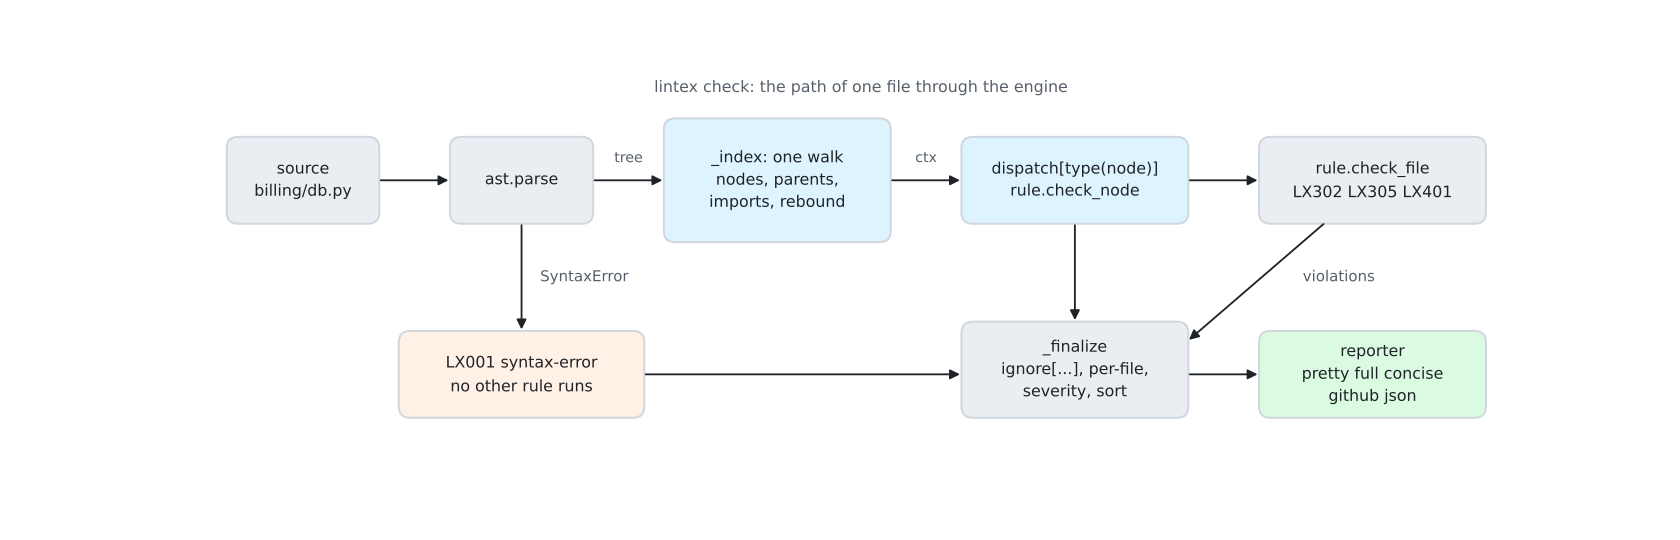

In [33]:
fig, ax = canvas(14, 4.5)
box(ax, 0.2, 2.8, 1.6, 0.9, "source\nbilling/db.py")
box(ax, 2.6, 2.8, 1.5, 0.9, "ast.parse")
box(ax, 4.9, 2.6, 2.4, 1.3, "_index: one walk\nnodes, parents,\nimports, rebound", kind="accent")
box(ax, 8.1, 2.8, 2.4, 0.9, "dispatch[type(node)]\nrule.check_node", kind="accent")
box(ax, 11.3, 2.8, 2.4, 0.9, "rule.check_file\nLX302 LX305 LX401")
box(ax, 2.05, 0.7, 2.6, 0.9, "LX001 syntax-error\nno other rule runs", kind="warn")
box(ax, 8.1, 0.7, 2.4, 1.0, "_finalize\nignore[...], per-file,\nseverity, sort", kind="step")
box(ax, 11.3, 0.7, 2.4, 0.9, "reporter\npretty full concise\ngithub json", kind="good")

arrow(ax, 1.8, 3.25, 2.6, 3.25)
arrow(ax, 4.1, 3.25, 4.9, 3.25, "tree")
arrow(ax, 7.3, 3.25, 8.1, 3.25, "ctx")
arrow(ax, 10.5, 3.25, 11.3, 3.25)
arrow(ax, 3.35, 2.8, 3.35, 1.6)
note(ax, 3.55, 2.2, "SyntaxError")
arrow(ax, 12.0, 2.8, 10.5, 1.5)
note(ax, 11.75, 2.2, "violations")
arrow(ax, 9.3, 2.8, 9.3, 1.7)
arrow(ax, 10.5, 1.15, 11.3, 1.15)
arrow(ax, 4.65, 1.15, 8.1, 1.15)
note(ax, 7.0, 4.25, "lintex check: the path of one file through the engine", fs=9.5, ha="center")
plt.show()

The dispatch table is an ordinary dict on the `Linter` instance. Listing it shows which rules pay attention to which nodes, and therefore why adding a rule that only cares about `ast.Call` costs nothing on the other 90 percent of nodes.

In [34]:
linter = Linter()
rows = [{"node type": f"ast.{t.__name__}", "rules": " ".join(r.code for r in rules), "n": len(rules)}
        for t, rules in linter._dispatch.items()]
dispatch = pd.DataFrame(rows).sort_values(["n", "node type"], ascending=[False, True]).reset_index(drop=True)
print("file-level rules:", " ".join(r.code for r in linter._file_rules))
dispatch

file-level rules: LX302 LX305 LX401


,node type,rules,n
0,ast.Call,LX101 LX201 LX203 LX204,4
1,ast.AsyncFunctionDef,LX301 LX303 LX304,3
2,ast.Attribute,LX101 LX102 LX205,3
3,ast.ExceptHandler,LX302 LX402 LX403,3
4,ast.FunctionDef,LX301 LX303 LX304,3
5,ast.Import,LX101 LX102 LX205,3
6,ast.ImportFrom,LX101 LX102 LX205,3
7,ast.Assert,LX302,1
8,ast.AsyncFor,LX302,1
9,ast.BinOp,LX201,1


What `_index` collects in that one walk, and which rule uses it:

| Collected | Example | Used by |
|---|---|---|
| `nodes` | Every node, in pre-order, as a flat list | The dispatch loop; no recursion during checking |
| `parents` | `JoinedStr -> Call -> Expr -> FunctionDef` | LX201 (skip nested f-strings), `is_compat_guarded`, LX302 (find the enclosing function) |
| `imports` | `{"pk": "pickle", "Mapping": "collections.Mapping"}` | `ctx.resolve`, so LX101/LX203/LX204/LX205 match fully qualified names regardless of alias |
| `rebound` | Names assigned, used as parameters, or defined in the file | `ctx.resolve` returns `None` for a shadowed name, so `def f(pickle): pickle.loads(x)` is not about the `pickle` module |
| `defined_functions` | `{"connect", "invoice_by_id"}` | LX101 skips `.iteritems()` if the file itself defines `iteritems` |

The walk is iterative (an explicit stack, `ast.iter_child_nodes` inlined) rather than a `NodeVisitor`, which is the part that keeps a 300k-line corpus near parse speed.

### Name resolution and compatibility guards

Two behaviours decide whether a security linter is usable on real code: it must see through aliases, and it must not flag code that is deliberately probing for an API. Both come from the index above.

In [35]:
cases = {
    "aliased import":        "import pickle as pk\n\ndef restore(blob):\n    return pk.loads(blob)\n",
    "shadowed name":         "def restore(pickle, blob):\n    return pickle.loads(blob)\n",
    "from-import":           "from pickle import loads\n\ndef restore(blob):\n    return loads(blob)\n",
    "compat guard":          "try:\n    from collections import Mapping\nexcept ImportError:\n    from collections.abc import Mapping\n",
    "version guard":         "import sys\nif sys.version_info < (3, 12):\n    from datetime import datetime\n    now = datetime.utcnow()\n",
    "unguarded":             "from collections import Mapping\n",
    "SQL in a variable":     "q = f\"SELECT * FROM invoices WHERE id = {invoice_id}\"\ncur.execute(q)\n",
    "SQL via .format later": "q = \"SELECT * FROM invoices WHERE id = {}\"\ncur.execute(q.format(invoice_id))\n",
    "bind list allowed":     "marks = ','.join('?' * len(ids))\ncur.execute(f\"SELECT * FROM invoices WHERE id IN ({marks})\", ids)\n",
}
rows = []
for label, src in cases.items():
    found = lint_source(src, path=f"{label}.py")
    rows.append({"case": label, "findings": ", ".join(f"{v.code}@{v.line}" for v in found) or "(clean)"})
pd.DataFrame(rows)

,case,findings
0,aliased import,LX203@4
1,shadowed name,(clean)
2,from-import,LX203@4
3,compat guard,(clean)
4,version guard,(clean)
5,unguarded,LX101@1
6,SQL in a variable,LX201@1
7,SQL via .format later,(clean)
8,bind list allowed,(clean)


Read the table against the index: `pk.loads` resolves to `pickle.loads` through `imports`; the parameter named `pickle` lands in `rebound` so the same call is left alone; `from pickle import loads` resolves `loads` to `pickle.loads` as well. The two guarded cases are skipped because `is_compat_guarded` walks `parents` up to a `try/except ImportError` or an `if` whose test mentions `sys.version_info`.

The last three rows are the SQL rule's reach and its edge. It fires on the f-string wherever it is built, not only inside `execute()`, so assigning the query to a variable first does not hide it. But `q.format(invoice_id)` on a template defined two lines earlier is clean: the rule needs to see the literal template at the call, and there is no data flow between statements. That is the honest limit of a single-pass AST linter and the first row of the limitations table below. The `IN (...)` bind-list idiom is allowed when the interpolated name contains `placeholder`, `bind` or `marks`; that is the one exception the rule makes, and it is a heuristic on the variable name.

### Writing a rule

A rule is a class with four attributes and one method. `node_types` says which nodes it wants; `check_node` yields violations built by `self.violation(ctx, node, message, why=..., fix=...)`, which fills in path, line, column and the source snippet. The AppSec rule most teams add first is a hard-coded secret check, so that is the one below.

lintex 0.1.0 has no plugin entry point: the README says to add a new rule class to `ALL_RULES` in `lintex/rules/__init__.py`, which means a fork or a pull request. For an experiment in-process, you can register a rule on a `Linter` instance by appending it to `rules` and to the private `_dispatch` table, as the cell does. The CLI will not see it; that is the honest limit of this approach.

In [36]:
import re
from lintex.rules.base import Rule
from lintex.models import Severity

class HardcodedSecretRule(Rule):
    code = "LX901"
    name = "hardcoded-secret"
    summary = "A variable whose name looks like a credential is assigned a string literal."
    default_severity = Severity.ERROR
    node_types = (ast.Assign,)
    options = {"min-length": 8}

    _NAME = re.compile(r"(secret|passw(or)?d|token|api_?key)$", re.IGNORECASE)

    def check_node(self, node, ctx):
        value = node.value
        if not (isinstance(value, ast.Constant) and isinstance(value.value, str)):
            return
        if len(value.value) < self.opts["min-length"]:
            return
        for target in node.targets:
            if isinstance(target, ast.Name) and self._NAME.search(target.id):
                yield self.violation(
                    ctx, node,
                    f"`{target.id}` is assigned a string literal; this looks like a hard-coded credential.",
                    why="Credentials in source end up in git history, build logs and every clone; "
                        "rotating them means a code change.",
                    fix="Read it from the environment or a secrets manager: "
                        f"`{target.id} = os.environ[\"{target.id.upper()}\"]`, and rotate the value that was committed.",
                )

def with_rule(linter, rule):
    linter.rules.append(rule)
    for node_type in rule.node_types:
        linter._dispatch[node_type].append(rule)
    return linter

linter = with_rule(Linter(), HardcodedSecretRule({"min-length": 12}))
sample = textwrap.dedent(f"""
    import os
    STRIPE_API_KEY = "sk_live_{fake.pystr(min_chars=24, max_chars=24)}"
    db_password = os.environ["DB_PASSWORD"]
    short_token = "abc"
""")
for v in linter.lint_source(sample, path="billing/settings.py"):
    print(f"{v.path}:{v.line}:{v.col} {v.code} [{v.severity.value}] {v.message}\n    fix: {v.fix}")

billing/settings.py:3:1 LX901 [error] `STRIPE_API_KEY` is assigned a string literal; this looks like a hard-coded credential.
    fix: Read it from the environment or a secrets manager: `STRIPE_API_KEY = os.environ["STRIPE_API_KEY"]`, and rotate the value that was committed.


One finding: the live key. The environment read on the next line is not a string literal, and the short token is under the threshold, so neither fires. Options are declared in `options` with their defaults; an unknown option name in the config raises a `ConfigError` with the valid list, which is the behaviour you get for free by subclassing `Rule`.

### Exit codes

Two different conventions are in play, and a CI author needs both.

| Command | Exit | Meaning |
|---|---|---|
| `lintex check` | 0 | Clean, or only findings below `--fail-on` (default `error`, so warnings alone pass) |
| `lintex check` | 1 | At least one finding at or above `--fail-on` |
| `lintex check` | 2 | Usage or configuration error (unknown rule, bad TOML, git failure under `--changed`) |
| `lintex check --exit-zero` | 0 | Always, for report-only jobs |
| `lintex hook claude-code` | 0 | Clean, or any problem in the hook itself (bad payload, bad config): the agent is never wedged |
| `lintex hook claude-code` | 2 | Findings at or above `--fail-on` (default `warning` here, stricter than `check`), stderr goes back to the model |

In [37]:
bad = WORK / "bad.toml"
bad.write_text('enable = ["LX999"]\n')
print("config error:")
proc = lx("check", "billing/models.py", "--config", str(bad), cwd=WORK)
print("\nwarnings only, default fail-on:")
proc = lx("check", "billing/tax.py", "--format", "concise", "--ignore", "LX301", cwd=WORK)
print("\nsame file with --fail-on warning:")
proc = lx("check", "billing/tax.py", "--format", "concise", "--ignore", "LX301", "--fail-on", "warning", cwd=WORK, show=False)
print(f"[exit {proc.returncode}]")

config error:


lintex: error: unknown rule 'LX999' in `enable`; run `lintex rules` to list rules
[exit 2]

warnings only, default fail-on:


billing/tax.py:4:1: LX302 Function `vat_rate()` has cyclomatic complexity 29 (limit 10).
▲ Found 1 warning in 1 file  · checked 1 file in 9 ms
  Each finding's `fix` line says what to write instead. `lintex explain CODE` has the full story;
  `# lintex: ignore[CODE]` silences a line on purpose.
[exit 0]

same file with --fail-on warning:


[exit 1]


### Performance

The README's claim is that cost is close to parsing alone. The cell below lints three stdlib packages from the running interpreter with one `Linter` and compares the time with a bare `ast.parse` of the same files. Numbers vary by machine; the ratio is the point.

In [38]:
import sysconfig
stdlib = Path(sysconfig.get_paths()["stdlib"])
corpus = [stdlib / name for name in ("email", "asyncio", "json")]

linter = Linter()
files = list(linter.iter_files(corpus))
lines = sum(len(p.read_bytes().splitlines()) for p in files)

t0 = time.perf_counter()
for p in files:
    try:
        ast.parse(p.read_bytes())
    except SyntaxError:
        pass
parse_ms = (time.perf_counter() - t0) * 1000

result = linter.lint_paths(corpus)

pd.DataFrame([
    {"measure": "files", "value": len(files)},
    {"measure": "lines", "value": lines},
    {"measure": "ast.parse only (ms)", "value": round(parse_ms)},
    {"measure": "lintex, all default rules (ms)", "value": round(result.duration_ms)},
    {"measure": "lintex / parse", "value": round(result.duration_ms / parse_ms, 2)},
    {"measure": "lines per second (lintex)", "value": round(lines / (result.duration_ms / 1000))},
    {"measure": "findings in the stdlib", "value": len(result.violations)},
]).set_index("measure")

,value
measure,
files,67.00
lines,26720.00
ast.parse only (ms),273.00
"lintex, all default rules (ms)",942.00
lintex / parse,3.45
lines per second (lintex),28352.00
findings in the stdlib,188.00


The stdlib is a hostile corpus for a linter aimed at agents (it is full of deliberate `os.system`, `pickle` and `/tmp` usage), which is exactly why `--changed` exists for adoption. The number to carry away is the ratio: the walk, the dispatch and all default rules together cost a small multiple of parsing, and a single edited file takes single-digit milliseconds, so running it after every agent edit has no visible latency.

### What lintex does not do

| Limitation | Consequence | What covers it |
|---|---|---|
| AST only, no type inference or data flow | SQL assembled in a helper and executed elsewhere, or a `verify` flag passed through a variable, is not seen | semgrep taint rules, CodeQL, review |
| LX102 checks names against the interpreter running lintex | Run it under the project's Python version, or a name that exists only on 3.13 is flagged on 3.11 | `requires-python` in `pyproject.toml` for LX101; a matching interpreter for LX102 |
| LX103 trusts the current environment | An import is "resolvable" if it is installed in the venv that runs lintex, whether or not it is declared | `pip check`, dependency pinning |
| Third-party hallucinations only from the curated pack | `openai.ChatCompletion` and `pydantic.BaseSettings` are known; a made-up method on your own SDK is not | mypy/pyright against the real stubs, tests |
| Placeholder detection is regex over comments | `# ... existing logic unchanged` is caught; `# ... existing validation logic unchanged` is not, because the pattern wants the noun right after `existing` (verified while writing Part 3) | review of the diff size: an edit that shrinks a file is the tell |
| No auto-fix | Every finding has a `fix` string, but nothing rewrites the file | the agent reads the fix; ruff for mechanical fixes |
| No plugin entry point | New rules need a fork, or in-process registration as above | contribute to `ALL_RULES` upstream |
| Python only | A Claude Code session editing SQL migrations, shell scripts or TypeScript is unchecked | per-language linters as sibling hooks |

The bigger point is in the README: lintex catches known agent mistakes, not wrong code. Pair it with ruff for general bugs, a type checker for invented methods on typed objects, and tests for whether it works at all.

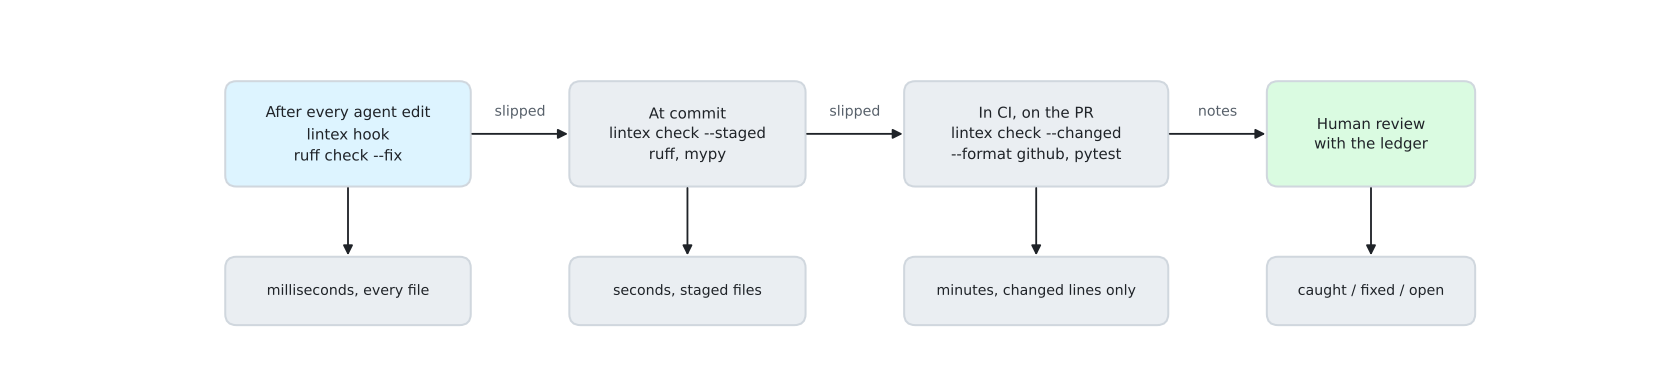

In [39]:
fig, ax = canvas(13.9, 3.2)
xs = [0.2, 3.9, 7.5, 11.4]
ws = [2.6, 2.5, 2.8, 2.2]
box(ax, xs[0], 1.7, ws[0], 1.1, "After every agent edit\nlintex hook\nruff check --fix", kind="accent", fs=9)
box(ax, xs[1], 1.7, ws[1], 1.1, "At commit\nlintex check --staged\nruff, mypy", fs=9)
box(ax, xs[2], 1.7, ws[2], 1.1, "In CI, on the PR\nlintex check --changed\n--format github, pytest", fs=9)
box(ax, xs[3], 1.7, ws[3], 1.1, "Human review\nwith the ledger", kind="good", fs=9)
for i, lab in enumerate(["slipped", "slipped", "notes"]):
    arrow(ax, xs[i] + ws[i], 2.25, xs[i + 1], 2.25, lab)
speed = ["milliseconds, every file", "seconds, staged files", "minutes, changed lines only", "caught / fixed / open"]
for x, w, t in zip(xs, ws, speed):
    box(ax, x, 0.2, w, 0.7, t, kind="step", fs=8.5)
    arrow(ax, x + w/2, 1.7, x + w/2, 0.9)
plt.show()

In [40]:
# Clean up the temp directories this notebook created.
for d in (WORK, REPO, REPO2):
    shutil.rmtree(d, ignore_errors=True)
print("removed", WORK.name, REPO.name, "and", REPO2.name)

removed gouldfoster-o3zfvupc repo-uvnxfoqy and refunds-ig0k6mvo


---

## Benchmark

The planted mistakes in the Setup cell are a labelled ground truth, so lintex can be scored rather than described. The same files go through ruff (with its security-minded `S` rules on) and bandit, the two tools a Python team would otherwise reach for, with the same scoring. Every number below comes from this run.

| Criterion | Why it matters | How it is measured | Target |
|---|---|---|---|
| Recall | A gate that misses the injection is worse than no gate, because people trust it | Planted lines on which the tool reports at least one finding, over all planted lines | at least 90 percent |
| Precision | Noise trains agents and reviewers to ignore the output | Findings on planted lines over all findings | at least 90 percent |
| Actionable findings | The hook only helps if the model can act without further context | Findings that carry a non-empty `fix` | 100 percent |
| Hook latency | It runs after every agent edit; a slow hook gets disabled | Median wall time of 5 subprocess runs on one file, interpreter startup included | under 300 ms |
| In-process cost | The engine's own cost, without startup | Median of 5 `Linter.lint_paths` runs over the service | under 20 ms |
| Rule coverage | A rule that never fires on a corpus built to trigger it is a bug | Default-on rules plus `LX103` that fire at least once on the planted files | at least 12 of 15 |
| Alternatives | A team that already runs ruff or bandit should know what they would gain | ruff `--select E,F,W,B,S,UP` and bandit on the same files, same scoring | reported in the same table |

In [41]:
# A pristine copy of the agent's files: the working copy was edited in Parts 2 and 3.
BENCH = Path(tempfile.mkdtemp(prefix="bench-"))
(BENCH / "billing").mkdir()
for rel, text in AGENT_FILES.items():
    (BENCH / rel).write_text(text)

# Ground truth: (file, substring that identifies the planted line, lintex code expected).
PLANTED = [
    ("billing/db.py", "except Exception:", "LX402"),
    ("billing/db.py", "f\"SELECT id, amount_cents", "LX201"),
    ("billing/db.py", "+ str(invoice_id)", "LX201"),
    ("billing/db.py", "rest of the implementation unchanged", "LX401"),
    ("billing/ops.py", "yaml.load(fh)", "LX203"),
    ("billing/ops.py", "pickle.loads(blob)", "LX203"),
    ("billing/ops.py", "os.system(", "LX203"),
    ("billing/ops.py", "shell=True", "LX203"),
    ("billing/ops.py", "tempfile.mktemp(", "LX204"),
    ("billing/ops.py", "0o777", "LX204"),
    ("billing/ops.py", "verify=False", "LX203"),
    ("billing/compat.py", "from collections import Mapping", "LX101"),
    ("billing/compat.py", "from os.path import joinpath", "LX102"),
    ("billing/compat.py", "import fastjsonschema_turbo", "LX103"),
    ("billing/compat.py", "datetime.utcnow()", "LX101"),
    ("billing/compat.py", "meta.iteritems()", "LX101"),
    ("billing/compat.py", "except:", "LX403"),
    ("billing/tax.py", "def vat_rate", "LX301"),
    ("billing/tax.py", "def vat_rate", "LX302"),
]
truth = []
for rel, needle, expected in PLANTED:
    lines = (BENCH / rel).read_text().splitlines()
    lineno = next(i for i, l in enumerate(lines, 1) if needle in l)
    truth.append({"path": rel, "line": lineno, "expected": expected})
truth = pd.DataFrame(truth)
truth_lines = set(zip(truth["path"], truth["line"]))
print(len(truth), "planted issues on", len(truth_lines), "distinct lines across", truth["path"].nunique(), "files")
truth.groupby("path")["expected"].agg(" ".join).to_frame()

19 planted issues on 18 distinct lines across 4 files


,expected
path,
billing/compat.py,LX101 LX102 LX103 LX101 LX101 LX403
billing/db.py,LX402 LX201 LX201 LX401
billing/ops.py,LX203 LX203 LX203 LX203 LX204 LX204 LX203
billing/tax.py,LX301 LX302


In [42]:
def timed(cmd, runs=5, cwd=BENCH):
    """Median wall time (ms) and the last CompletedProcess of `runs` subprocess runs."""
    times = []
    for _ in range(runs):
        t0 = time.perf_counter()
        proc = subprocess.run(cmd, cwd=cwd, capture_output=True, text=True, env=ENV)
        times.append((time.perf_counter() - t0) * 1000)
    return sorted(times)[len(times) // 2], proc

PY = [sys.executable, "-m"]
tools = {}

def rel(path):
    """Tool output paths may be absolute (ruff) or relative (bandit); normalise to billing/x.py."""
    p = Path(path)
    return str(p.relative_to(BENCH)) if p.is_absolute() else str(p)

ms, proc = timed([*PY, "lintex", "check", "billing", "--json", "--enable", "LX103"])
tools["lintex"] = (ms, [{"path": v["path"], "line": v["line"], "code": v["code"], "fix": v["fix"]}
                        for v in json.loads(proc.stdout)["violations"]])

ms, proc = timed([*PY, "ruff", "check", "billing", "--select", "E,F,W,B,S,UP", "--output-format", "json", "--no-cache"])
tools["ruff"] = (ms, [{"path": rel(v["filename"]), "line": v["location"]["row"],
                       "code": v["code"], "fix": (v.get("fix") or {}).get("message") or ""}
                      for v in json.loads(proc.stdout)])

ms, proc = timed([*PY, "bandit", "-q", "-r", "billing", "-f", "json"])
tools["bandit"] = (ms, [{"path": rel(v["filename"]), "line": v["line_number"],
                         "code": v["test_id"], "fix": ""}
                        for v in json.loads(proc.stdout)["results"]])

ms_single, _ = timed([*PY, "lintex", "check", "billing/db.py", "--json"])

linter = Linter(load_config(BENCH))
inproc = []
for _ in range(5):
    t0 = time.perf_counter(); linter.lint_paths([BENCH / "billing"]); inproc.append((time.perf_counter() - t0) * 1000)
ms_inproc = sorted(inproc)[2]

rows = []
for name, (ms, found) in tools.items():
    on_truth = {(f["path"], f["line"]) for f in found} & truth_lines
    rows.append({
        "tool": name,
        "findings": len(found),
        "planted lines caught": len(on_truth),
        "recall %": round(100 * len(on_truth) / len(truth_lines), 1),
        "precision %": round(100 * sum((f["path"], f["line"]) in truth_lines for f in found) / max(len(found), 1), 1),
        "with a fix text %": round(100 * sum(bool(f["fix"]) for f in found) / max(len(found), 1), 1),
        "wall ms (median of 5, 6 files)": round(ms),
    })
compare = pd.DataFrame(rows).set_index("tool")
compare

,findings,planted lines caught,recall %,precision %,with a fix text %,"wall ms (median of 5, 6 files)"
tool,,,,,,
lintex,19,18,100.0,100.0,100.0,170
ruff,17,12,66.7,94.1,11.8,62
bandit,13,10,55.6,84.6,0.0,368


In [43]:
# Which planted issue did each tool catch, and what did each report that was not planted.
matrix = truth.copy()
for name, (_, found) in tools.items():
    by_line = {}
    for f in found:
        by_line.setdefault((f["path"], f["line"]), []).append(f["code"])
    matrix[name] = [" ".join(sorted(set(by_line.get(k, [])))) or "-" for k in zip(matrix["path"], matrix["line"])]
matrix["lintex code matched"] = [exp in cell.split() for exp, cell in zip(matrix["expected"], matrix["lintex"])]
matrix

,path,line,expected,lintex,ruff,bandit,lintex code matched
0,billing/db.py,10,LX402,LX402,S110,B110,True
1,billing/db.py,21,LX201,LX201,E501 S608,B608,True
2,billing/db.py,26,LX201,LX201,S608,B608,True
3,billing/db.py,27,LX401,LX401,-,-,True
4,billing/ops.py,15,LX203,LX203,S506,B506,True
5,billing/ops.py,19,LX203,LX203,S301,B301,True
6,billing/ops.py,23,LX203,LX203,S605 UP031,B605,True
7,billing/ops.py,24,LX203,LX203,E501 S602,B602,True
8,billing/ops.py,28,LX204,LX204,S306,B306,True
9,billing/ops.py,32,LX204,LX204,S103,B103,True


In [44]:
extras = []
for name, (_, found) in tools.items():
    for f in found:
        if (f["path"], f["line"]) not in truth_lines:
            extras.append({"tool": name, "path": f["path"], "line": f["line"], "code": f["code"]})
extras = pd.DataFrame(extras)
print("findings outside the planted set:", len(extras))
extras.sort_values(["tool", "path", "line"]).reset_index(drop=True)

findings outside the planted set: 3


,tool,path,line,code
0,bandit,billing/ops.py,3,B403
1,bandit,billing/ops.py,4,B404
2,ruff,billing/db.py,15,E501


Read the extras before the scorecard. A finding outside the planted set is not automatically wrong: it is a line the author of this notebook did not label. The lintex extras, if any, are listed with their codes so you can judge them; bandit's `B403`/`B404` are warnings that `pickle` and `subprocess` were imported at all, which is the kind of finding a reviewer learns to scroll past.

In [45]:
fired = {f["code"] for f in tools["lintex"][1]}
default_on = [r.code for r in lintex.rules.ALL_RULES if r.default_enabled and r.code != "LX001"]
coverage = sorted(set(default_on + ["LX103"]) & fired)
silent = sorted(set(default_on) - fired)

lx_row = compare.loc["lintex"]
score = pd.DataFrame([
    {"criterion": "Recall on planted lines", "measured": f"{lx_row['recall %']} %", "target": ">= 90 %", "met": lx_row["recall %"] >= 90},
    {"criterion": "Precision", "measured": f"{lx_row['precision %']} %", "target": ">= 90 %", "met": lx_row["precision %"] >= 90},
    {"criterion": "Findings with a fix", "measured": f"{lx_row['with a fix text %']} %", "target": "100 %", "met": lx_row["with a fix text %"] == 100},
    {"criterion": "Hook latency, one file, subprocess", "measured": f"{ms_single:.0f} ms", "target": "< 300 ms", "met": ms_single < 300},
    {"criterion": "In-process, 6 files", "measured": f"{ms_inproc:.1f} ms", "target": "< 20 ms", "met": ms_inproc < 20},
    {"criterion": "Rule coverage on the corpus", "measured": f"{len(coverage)} of {len(default_on) + 1} ({' '.join(coverage)})", "target": ">= 12", "met": len(coverage) >= 12},
    {"criterion": "ruff recall / precision, same files", "measured": f"{compare.loc['ruff', 'recall %']} % / {compare.loc['ruff', 'precision %']} %", "target": "reported", "met": True},
    {"criterion": "bandit recall / precision, same files", "measured": f"{compare.loc['bandit', 'recall %']} % / {compare.loc['bandit', 'precision %']} %", "target": "reported", "met": True},
])
score["met"] = score["met"].map({True: "yes", False: "no"})
print("rules that never fired:", " ".join(silent) or "none")
for _, r in score[score["met"] == "no"].iterrows():
    print(f"MISS  {r['criterion']}: measured {r['measured']} against {r['target']}")
score.set_index("criterion")

rules that never fired: LX205 LX303 LX304 LX305
MISS  Rule coverage on the corpus: measured 11 of 15 (LX101 LX102 LX103 LX201 LX203 LX204 LX301 LX302 LX401 LX402 LX403) against >= 12


,measured,target,met
criterion,,,
Recall on planted lines,100.0 %,>= 90 %,yes
Precision,100.0 %,>= 90 %,yes
Findings with a fix,100.0 %,100 %,yes
"Hook latency, one file, subprocess",196 ms,< 300 ms,yes
"In-process, 6 files",8.2 ms,< 20 ms,yes
Rule coverage on the corpus,11 of 15 (LX101 LX102 LX103 LX201 LX203 LX204 ...,>= 12,no
"ruff recall / precision, same files",66.7 % / 94.1 %,reported,yes
"bandit recall / precision, same files",55.6 % / 84.6 %,reported,yes


What the scorecard does and does not say. Recall and precision are measured on a corpus written to trigger lintex's own rules, so lintex's numbers are an upper bound and ruff's and bandit's are a floor: both tools catch the classic sinks (SQL strings, `yaml.load`, `pickle`, `shell=True`, `verify=False`, `mktemp`, `0o777`) and neither has any notion of a removed stdlib name, a hallucinated package, or a comment standing in for deleted code. The planted file for those three families is `compat.py` plus one line of `db.py`, and that is where the recall gap between the tools comes from.

Rules that did not fire are listed above the table. `LX303`, `LX304` and `LX305` have no planted trigger in this corpus (parameter count, nesting depth, module length), and `LX205` only fires with a `banned-api` config, which the benchmark runs without. If a precision miss is printed, the lines in the extras table are the ones to look at; each is either an unlabelled true positive or a false positive, and the notebook does not decide that for you.

Latency is measured with interpreter startup included for the hook row, because that is what the agent waits for; the in-process row is the engine alone. Both are on a shared machine, so treat them as an order of magnitude, not a benchmark result to quote.

In [46]:
shutil.rmtree(BENCH, ignore_errors=True)
print("removed", BENCH.name)

removed bench-vxqn7n0j


## Cheat sheet

| Step | Command or call | Notes |
|---|---|---|
| Install | `pip install lintex` | `lintex[yaml]` for `.lintex.yaml` |
| Lint a path | `lintex check billing/db.py` | `lintex` alone lints `.`; exit 1 on errors |
| Machine output | `lintex check billing --json` | Same shape as `LintResult.to_dict()` |
| Other formats | `lintex check --format concise\|github\|full` | `-v` repeats `why` in pretty output |
| List rules | `lintex rules` | Reflects the current config (`on`/`off`) |
| Explain a rule | `lintex explain LX204` | Rationale and `[rules.<name>]` options |
| Configure | `.lintex.toml` or `[tool.lintex]` in `pyproject.toml` | `enable`, `ignore`, `select`, `severity`, `per-file-ignores`, `exclude`, `fail-on`, `rules.<name>.<option>` |
| Override on the CLI | `--select LX2 --ignore LX403 --enable LX103 --fail-on warning` | Prefixes work for `select`/`ignore` |
| Silence a line | `# lintex: ignore[LX203]` | `# lintex: ignore` for all rules, `# lintex: skip-file` for the file |
| Only the diff | `lintex check --changed=main` | Findings on changed lines; new files in full |
| Only the index | `lintex check --staged` | What the commit will contain |
| Pre-commit hook | `lintex install-hook git` | `--force` to replace a foreign hook |
| Claude Code hook | `lintex install-hook claude-code` | `--scope local\|user`; the hook is `lintex hook claude-code`, exit 2 on findings |
| Session ledger | `lintex report`, `lintex statusline` | `--since 7d`, `--all`, `--session ID`, `--json`, `--clear`; `LINTEX_LEDGER_DIR` relocates it |
| Library | `lint_source(code, path=...)`, `Linter(load_config(".")).lint_paths([...])` | `Violation` fields: `code rule message path line col severity why fix snippet` |
| New rule | subclass `lintex.rules.base.Rule`, set `code name summary node_types`, implement `check_node` | Ship it by adding to `ALL_RULES` in `lintex/rules/__init__.py` |

## Where it fits

| Tool | Catches | Misses | When to run | Cost per file |
|---|---|---|---|---|
| **lintex** | Hallucinated and removed APIs, SQL interpolation, dangerous sinks, insecure file ops, elided code, silenced exceptions, bloat; each with a `why` and `fix` an agent can act on | Wrong logic, data flow across functions, non-Python | Every agent edit (hook), commit, CI on changed lines | milliseconds |
| ruff | Hundreds of general bug and style patterns, unused imports, undefined names, some `S` (bandit) rules | Agent-specific artifacts, `why`/`fix` text for a model | Every agent edit, commit | milliseconds |
| bandit | Security sinks across the stdlib and common libraries, with confidence levels | Hallucinated APIs, placeholders, anything the agent invented | Commit, CI | sub-second |
| semgrep | Taint tracking and your own patterns across many languages | Needs rules written for the project | CI | seconds |
| mypy / pyright | Invented methods on typed objects, wrong argument counts, `None` misuse | Anything untyped or string-shaped (SQL, shell) | Commit, CI | seconds to minutes |
| pytest | Whether the code does what was asked | Everything the tests do not cover | Commit, CI | depends |

lintex is the first, cheapest layer and the only one written to talk back to the agent. The rest of the stack is still needed; the README's recommended setup is lintex and ruff as sibling `PostToolUse` hooks, then mypy and pytest at commit and in CI.